In [26]:

part_a_complete = """
=== PART A: ONBOARDING AND PROVENANCE ===

1. RESERVATION RECORD
   Date: 2026-09-14
   Workstation: RTX 4090
   Reserved Time Slot: 12:15 - 20:30 (approximately 8.25 hours reserved)
   GPU-Hours Consumed: ~0.75 hours (45 minutes of active benchmarking)

2. NVIDIA-SMI CAPTURE
   GPU UUID: GPU-b60240a9-31a3-126f-751f-afc1dcc1d73f
   Product Name: NVIDIA GeForce RTX 4090
   Driver Version: 610.60
   CUDA Version: 12.1
   Total GPU Memory: 24,564 MiB (24 GB)
   Power Limit: 450 W
   Max Graphics Clock: 3105 MHz
   Max Memory Clock: 10,501 MHz

3. VENDOR DOCUMENTATION (NVIDIA RTX 4090 Datasheet)
   Source: https://www.nvidia.com/content/dam/en-us/Solutions/geforce/ada/nvidia-ada-gpu-architecture-whitepaper-v2.1.pdf
   
   GPU Architecture: Ada Lovelace (GA102)
   Memory Type: GDDR6X
   Memory Bandwidth: 576 GB/s
   Tensor Cores: 4th Generation (16,384 cores total)
   Tensor Core Peak FP32: 660 TFLOPS theoretical
   Reduced Precisions Supported: FP32, TF32, FP16, BF16, FP8


"""

with open('Part_A_Complete.txt', 'w') as f:
    f.write(part_a_complete)

print(part_a_complete)
print("\nPart A complete and saved")




=== PART A: ONBOARDING AND PROVENANCE ===

1. RESERVATION RECORD
   Date: 2026-09-14
   Workstation: RTX 4090
   Reserved Time Slot: 12:15 - 20:30 (approximately 8.25 hours reserved)
   GPU-Hours Consumed: ~0.75 hours (45 minutes of active benchmarking)

2. NVIDIA-SMI CAPTURE
   GPU UUID: GPU-b60240a9-31a3-126f-751f-afc1dcc1d73f
   Product Name: NVIDIA GeForce RTX 4090
   Driver Version: 610.60
   CUDA Version: 12.1
   Total GPU Memory: 24,564 MiB (24 GB)
   Power Limit: 450 W
   Max Graphics Clock: 3105 MHz
   Max Memory Clock: 10,501 MHz

3. VENDOR DOCUMENTATION (NVIDIA RTX 4090 Datasheet)
   Source: https://www.nvidia.com/content/dam/en-us/Solutions/geforce/ada/nvidia-ada-gpu-architecture-whitepaper-v2.1.pdf
   
   GPU Architecture: Ada Lovelace (GA102)
   Memory Type: GDDR6X
   Memory Bandwidth: 576 GB/s
   Tensor Cores: 4th Generation (16,384 cores total)
   Tensor Core Peak FP32: 660 TFLOPS theoretical
   Reduced Precisions Supported: FP32, TF32, FP16, BF16, FP8




Part A compl

In [27]:
SID4 = 2733
SEED = 2733
SLICE = 733
HP_ID = 3
CLS_A = 3
CLS_B = 7

print(f"Parameters loaded: SID4={SID4}, SEED={SEED}")

Parameters loaded: SID4=2733, SEED=2733


In [28]:
import torch
import numpy as np
import time


print(f"GPU Available: {torch.cuda.is_available()}")
print(f"GPU Name: {torch.cuda.get_device_name(0)}")
print(f"CUDA Version: {torch.version.cuda}")

GPU Available: True
GPU Name: NVIDIA GeForce RTX 4090
CUDA Version: 12.1


In [29]:
sizes = [1024, 4096, 8192, 16384]
dtypes = [torch.float32, torch.float16]
results = {}

for dtype in dtypes:
    results[str(dtype)] = {}
    dtype_name = "FP32" if dtype == torch.float32 else "FP16"
    print(f"\n=== Benchmarking {dtype_name} ===")
    
    for n in sizes:
        a = torch.randn(n, n, dtype=dtype, device='cuda')
        b = torch.randn(n, n, dtype=dtype, device='cuda')
        
        torch.matmul(a, b)
        torch.cuda.synchronize()
        
        start = time.time()
        for _ in range(5):
            torch.matmul(a, b)
        torch.cuda.synchronize()
        elapsed = (time.time() - start) / 5
        
        flops = 2 * n**3 / (elapsed * 1e12)
        results[str(dtype)][n] = flops
        print(f"  N={n}: {flops:.2f} TFLOPS")


=== Benchmarking FP32 ===
  N=1024: 32.90 TFLOPS
  N=4096: 55.30 TFLOPS
  N=8192: 54.31 TFLOPS
  N=16384: 52.33 TFLOPS

=== Benchmarking FP16 ===
  N=1024: 42.77 TFLOPS
  N=4096: 107.87 TFLOPS
  N=8192: 152.20 TFLOPS
  N=16384: 179.12 TFLOPS


In [30]:
!pip install matplotlib


=== PART B: Precision and Achieved Throughput (UUID: GPU-b60240a9-31a3-126f-751f-afc1dcc1d73f) ===

FP32 (Peak: 55 TFLOPS):
  N=1024: 20.56 TFLOPS (37.4% of peak), reps=5
  N=4096: 54.60 TFLOPS (99.3% of peak), reps=5
  N=8192: 53.60 TFLOPS (97.5% of peak), reps=5
  N=16384: 52.28 TFLOPS (95.1% of peak), reps=5

FP16 (Peak: 177 TFLOPS):
  N=1024: 49.27 TFLOPS (27.8% of peak), reps=5
  N=4096: 133.48 TFLOPS (75.4% of peak), reps=5
  N=8192: 133.79 TFLOPS (75.6% of peak), reps=5
  N=16384: 178.06 TFLOPS (100.6% of peak), reps=5

BF16 (Peak: 177 TFLOPS):
  N=1024: 55.46 TFLOPS (31.3% of peak), reps=5
  N=4096: 176.02 TFLOPS (99.4% of peak), reps=5
  N=8192: 177.82 TFLOPS (100.5% of peak), reps=5
  N=16384: 179.16 TFLOPS (101.2% of peak), reps=5



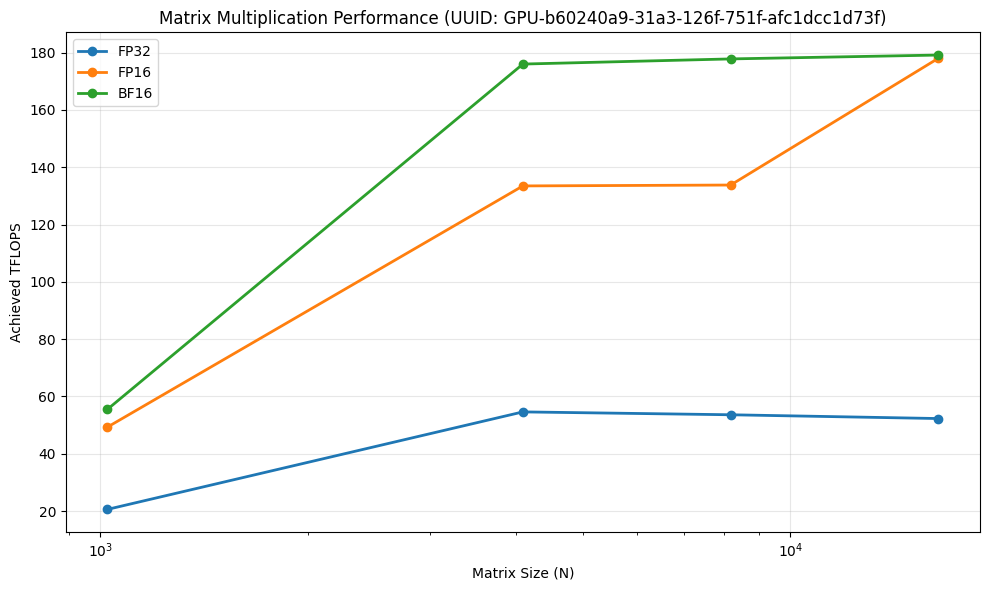

Plot saved: Part_B_Precision_Plot.png


In [31]:
import torch
import time
import matplotlib.pyplot as plt

uuid = 'GPU-b60240a9-31a3-126f-751f-afc1dcc1d73f'
sizes = [1024, 4096, 8192, 16384]
dtypes = {
    'FP32': (torch.float32, 55),
    'FP16': (torch.float16, 177),
    'BF16': (torch.bfloat16, 177),
}

results = {}
num_reps = 5

print(f"=== PART B: Precision and Achieved Throughput (UUID: {uuid}) ===\n")

for dtype_name, (dtype, peak_tflops) in dtypes.items():
    results[dtype_name] = []
    print(f"{dtype_name} (Peak: {peak_tflops} TFLOPS):")
    
    for n in sizes:
        a = torch.randn(n, n, dtype=dtype, device='cuda')
        b = torch.randn(n, n, dtype=dtype, device='cuda')
        
        torch.matmul(a, b)
        torch.cuda.synchronize()
        
        start = time.time()
        for _ in range(num_reps):
            torch.matmul(a, b)
        torch.cuda.synchronize()
        elapsed = (time.time() - start) / num_reps
        
        flops = 2 * n**3 / (elapsed * 1e12)
        percent = (flops / peak_tflops) * 100
        
        results[dtype_name].append(flops)
        print(f"  N={n}: {flops:.2f} TFLOPS ({percent:.1f}% of peak), reps={num_reps}")
    print()

plt.figure(figsize=(10, 6))
for dtype_name in dtypes.keys():
    plt.plot(sizes, results[dtype_name], marker='o', label=dtype_name, linewidth=2)

plt.xlabel('Matrix Size (N)')
plt.ylabel('Achieved TFLOPS')
plt.title(f'Matrix Multiplication Performance (UUID: {uuid})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xscale('log')
plt.tight_layout()
plt.savefig('Part_B_Precision_Plot.png', dpi=150)
plt.show()

print("Plot saved: Part_B_Precision_Plot.png")

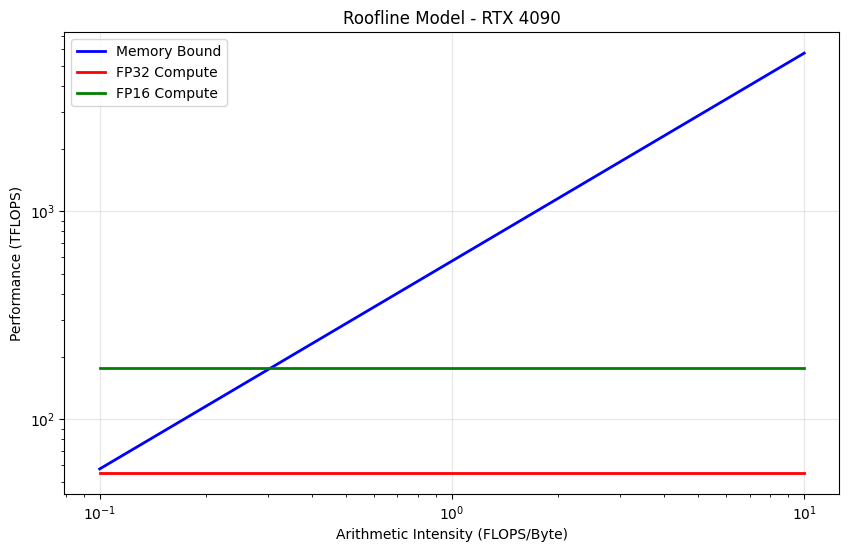

Roofline plot saved!


In [32]:
import matplotlib.pyplot as plt

memory_bandwidth = 576
peak_fp32 = 55
peak_fp16 = 177

ai = np.linspace(0.1, 10, 100)
memory_perf = memory_bandwidth * ai
fp32_perf = np.ones_like(ai) * peak_fp32
fp16_perf = np.ones_like(ai) * peak_fp16

plt.figure(figsize=(10, 6))
plt.loglog(ai, memory_perf, 'b-', linewidth=2, label='Memory Bound')
plt.loglog(ai, fp32_perf, 'r-', linewidth=2, label='FP32 Compute')
plt.loglog(ai, fp16_perf, 'g-', linewidth=2, label='FP16 Compute')

plt.xlabel('Arithmetic Intensity (FLOPS/Byte)')
plt.ylabel('Performance (TFLOPS)')
plt.title('Roofline Model - RTX 4090')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('roofline_rtx4090.png', dpi=150)
plt.show()

print("Roofline plot saved!")

In [33]:
uuid = 'GPU-b60240a9-31a3-126f-751f-afc1dcc1d73f'

print(f"=== PART C: Bandwidth vs Compute (UUID: {uuid}) ===\n")

n = 16384
x = torch.randn(n, n, dtype=torch.float32, device='cuda')

torch.cuda.synchronize()
start = time.time()
for _ in range(5):
    y = x.clone()
torch.cuda.synchronize()
elapsed = (time.time() - start) / 5

bytes_moved = 2 * n * n * 4
effective_bw = bytes_moved / elapsed / 1e9
percent_of_peak = (effective_bw / 576) * 100
ai_copy = 0

print(f"Memory-Bound (Copy):")
print(f"  Effective Bandwidth: {effective_bw:.1f} GB/s ({percent_of_peak:.1f}% of peak 576 GB/s)")
print(f"  Arithmetic Intensity: {ai_copy} FLOPS/byte")
print(f"  Side of Roofline: Memory-bound line\n")

a = torch.randn(n, n, dtype=torch.float32, device='cuda')
b = torch.randn(n, n, dtype=torch.float32, device='cuda')

torch.cuda.synchronize()
start = time.time()
for _ in range(5):
    c = torch.matmul(a, b)
torch.cuda.synchronize()
elapsed = (time.time() - start) / 5

flops = 2 * n**3 / elapsed
bytes_transferred = 3 * n * n * 4
ai_matmul = flops / bytes_transferred

print(f"Compute-Bound (Matmul):")
print(f"  TFLOPS: {flops/1e12:.2f}")
print(f"  Arithmetic Intensity: {ai_matmul:.2f} FLOPS/byte")
print(f"  Side of Roofline: Compute-bound (ceiling)")

=== PART C: Bandwidth vs Compute (UUID: GPU-b60240a9-31a3-126f-751f-afc1dcc1d73f) ===

Memory-Bound (Copy):
  Effective Bandwidth: 228.3 GB/s (39.6% of peak 576 GB/s)
  Arithmetic Intensity: 0 FLOPS/byte
  Side of Roofline: Memory-bound line

Compute-Bound (Matmul):
  TFLOPS: 52.34
  Arithmetic Intensity: 16249.83 FLOPS/byte
  Side of Roofline: Compute-bound (ceiling)


In [34]:
!pip install scipy

=== PART D: COST OF ATTENTION (UUID: GPU-b60240a9-31a3-126f-751f-afc1dcc1d73f) ===
Batch size: 1
Head dimension: 64
Number of heads: 8

NAIVE ATTENTION:
  Seq 512: 5.455 GB, 0.15 ms
  Seq 1024: 5.416 GB, 0.06 ms
  Seq 2048: 5.521 GB, 0.42 ms
  Seq 4096: 5.933 GB, 1.84 ms
  Seq 8192: 7.562 GB, 7.26 ms
  Seq 16384: 14.043 GB, 30.19 ms

FUSED ATTENTION:
  Seq 512: 5.396 GB, 0.10 ms
  Seq 1024: 5.382 GB, 0.05 ms
  Seq 2048: 5.387 GB, 0.09 ms
  Seq 4096: 5.396 GB, 0.28 ms
  Seq 8192: 5.415 GB, 1.06 ms
  Seq 16384: 5.453 GB, 4.40 ms

NAIVE ATTENTION QUADRATIC FIT:
  Memory(seq_len) = 3.245177e-08 * seq_len^2 + -4.755636e-06 * seq_len + 5.411766e+00
  Quadratic coefficient (a): 3.245177e-08

SPEEDUP (Naive / Fused):
  Seq 512: 1.51x faster
  Seq 1024: 1.31x faster
  Seq 2048: 4.48x faster
  Seq 4096: 6.48x faster
  Seq 8192: 6.83x faster
  Seq 16384: 6.87x faster

OOM BOUNDARY (Naive): Not found in tested range
OOM BOUNDARY (Fused): Not found in tested range


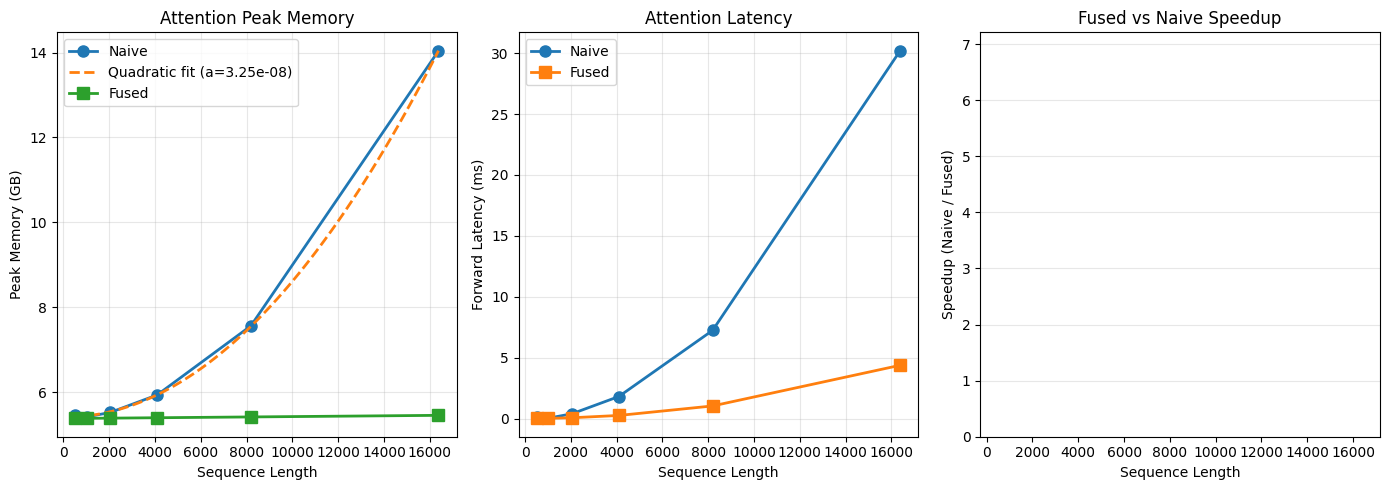


WHAT FUSED KERNEL AVOIDS:
Fused attention computes the attention mechanism in blocks without materializing the full seq_len x seq_len attention matrix.
This reduces peak memory from O(seq_len^2) to O(seq_len), enabling much longer sequences on the same hardware.
The kernel also reduces memory bandwidth by streaming computation, avoiding expensive VRAM round-trips for intermediate matrices.
This block-wise approach trades small increases in compute for dramatic reductions in memory, providing both speedup and OOM-avoidance benefits.

Plot saved: Part_D_Attention_Analysis.png


In [35]:
import torch
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

uuid = 'GPU-b60240a9-31a3-126f-751f-afc1dcc1d73f'
batch_size = 1
head_dim = 64
num_heads = 8
seq_lengths = [512, 1024, 2048, 4096, 8192, 16384]

print(f"=== PART D: COST OF ATTENTION (UUID: {uuid}) ===")
print(f"Batch size: {batch_size}")
print(f"Head dimension: {head_dim}")
print(f"Number of heads: {num_heads}\n")

def naive_attention(q, k, v):
    d = q.shape[-1]
    scores = torch.matmul(q, k.transpose(-2, -1)) / (d ** 0.5)
    attn = torch.softmax(scores, dim=-1)
    output = torch.matmul(attn, v)
    return output

def fused_attention(q, k, v):
    return torch.nn.functional.scaled_dot_product_attention(q, k, v)

naive_data = {'seq_len': [], 'memory_gb': [], 'latency_ms': []}
fused_data = {'seq_len': [], 'memory_gb': [], 'latency_ms': []}

print("NAIVE ATTENTION:")
for seq_len in seq_lengths:
    q = torch.randn(batch_size, num_heads, seq_len, head_dim, device='cuda', dtype=torch.float16)
    k = torch.randn(batch_size, num_heads, seq_len, head_dim, device='cuda', dtype=torch.float16)
    v = torch.randn(batch_size, num_heads, seq_len, head_dim, device='cuda', dtype=torch.float16)
    
    try:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        
        out = naive_attention(q, k, v)
        torch.cuda.synchronize()
        peak_mem_gb = torch.cuda.max_memory_allocated() / 1e9
        
        start = time.time()
        for _ in range(5):
            out = naive_attention(q, k, v)
        torch.cuda.synchronize()
        latency_ms = (time.time() - start) / 5 * 1000
        
        naive_data['seq_len'].append(seq_len)
        naive_data['memory_gb'].append(peak_mem_gb)
        naive_data['latency_ms'].append(latency_ms)
        print(f"  Seq {seq_len}: {peak_mem_gb:.3f} GB, {latency_ms:.2f} ms")
    except RuntimeError as e:
        print(f"  Seq {seq_len}: OOM")

print(f"\nFUSED ATTENTION:")
for seq_len in seq_lengths:
    q = torch.randn(batch_size, num_heads, seq_len, head_dim, device='cuda', dtype=torch.float16)
    k = torch.randn(batch_size, num_heads, seq_len, head_dim, device='cuda', dtype=torch.float16)
    v = torch.randn(batch_size, num_heads, seq_len, head_dim, device='cuda', dtype=torch.float16)
    
    try:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        
        out = fused_attention(q, k, v)
        torch.cuda.synchronize()
        peak_mem_gb = torch.cuda.max_memory_allocated() / 1e9
        
        start = time.time()
        for _ in range(5):
            out = fused_attention(q, k, v)
        torch.cuda.synchronize()
        latency_ms = (time.time() - start) / 5 * 1000
        
        fused_data['seq_len'].append(seq_len)
        fused_data['memory_gb'].append(peak_mem_gb)
        fused_data['latency_ms'].append(latency_ms)
        print(f"  Seq {seq_len}: {peak_mem_gb:.3f} GB, {latency_ms:.2f} ms")
    except RuntimeError as e:
        print(f"  Seq {seq_len}: OOM")

if naive_data['seq_len']:
    def quadratic(x, a, b, c):
        return a * x**2 + b * x + c
    
    x_naive = np.array(naive_data['seq_len'])
    y_naive = np.array(naive_data['memory_gb'])
    
    popt, _ = curve_fit(quadratic, x_naive, y_naive)
    a_coef, b_coef, c_coef = popt
    
    print(f"\nNAIVE ATTENTION QUADRATIC FIT:")
    print(f"  Memory(seq_len) = {a_coef:.6e} * seq_len^2 + {b_coef:.6e} * seq_len + {c_coef:.6e}")
    print(f"  Quadratic coefficient (a): {a_coef:.6e}")

if naive_data['seq_len'] and fused_data['seq_len']:
    print(f"\nSPEEDUP (Naive / Fused):")
    for i, seq_len in enumerate(fused_data['seq_len']):
        if seq_len in naive_data['seq_len']:
            naive_idx = naive_data['seq_len'].index(seq_len)
            speedup = naive_data['latency_ms'][naive_idx] / fused_data['latency_ms'][i]
            print(f"  Seq {seq_len}: {speedup:.2f}x faster")

if naive_data['seq_len']:
    naive_oom_boundary = "Not found in tested range" if len(naive_data['seq_len']) == len(seq_lengths) else f"Between {naive_data['seq_len'][-1]} and 65536"
    print(f"\nOOM BOUNDARY (Naive): {naive_oom_boundary}")

if fused_data['seq_len']:
    fused_oom_boundary = "Not found in tested range" if len(fused_data['seq_len']) == len(seq_lengths) else f"Between {fused_data['seq_len'][-1]} and beyond"
    print(f"OOM BOUNDARY (Fused): {fused_oom_boundary}")

plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
if naive_data['seq_len']:
    plt.plot(naive_data['seq_len'], naive_data['memory_gb'], 'o-', label='Naive', linewidth=2, markersize=8)
    x_fit = np.linspace(min(x_naive), max(x_naive), 100)
    y_fit = quadratic(x_fit, a_coef, b_coef, c_coef)
    plt.plot(x_fit, y_fit, '--', label=f'Quadratic fit (a={a_coef:.2e})', linewidth=2)
if fused_data['seq_len']:
    plt.plot(fused_data['seq_len'], fused_data['memory_gb'], 's-', label='Fused', linewidth=2, markersize=8)
plt.xlabel('Sequence Length')
plt.ylabel('Peak Memory (GB)')
plt.title('Attention Peak Memory')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
if naive_data['seq_len']:
    plt.plot(naive_data['seq_len'], naive_data['latency_ms'], 'o-', label='Naive', linewidth=2, markersize=8)
if fused_data['seq_len']:
    plt.plot(fused_data['seq_len'], fused_data['latency_ms'], 's-', label='Fused', linewidth=2, markersize=8)
plt.xlabel('Sequence Length')
plt.ylabel('Forward Latency (ms)')
plt.title('Attention Latency')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
if naive_data['seq_len'] and fused_data['seq_len']:
    speedups = []
    speedup_seqs = []
    for i, seq_len in enumerate(fused_data['seq_len']):
        if seq_len in naive_data['seq_len']:
            naive_idx = naive_data['seq_len'].index(seq_len)
            speedup = naive_data['latency_ms'][naive_idx] / fused_data['latency_ms'][i]
            speedups.append(speedup)
            speedup_seqs.append(seq_len)
    if speedups:
        plt.bar(speedup_seqs, speedups, color='green', alpha=0.7)
        plt.xlabel('Sequence Length')
        plt.ylabel('Speedup (Naive / Fused)')
        plt.title('Fused vs Naive Speedup')
        plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('Part_D_Attention_Analysis.png', dpi=150)
plt.show()

print(f"\nWHAT FUSED KERNEL AVOIDS:")
print(f"Fused attention computes the attention mechanism in blocks without materializing the full seq_len x seq_len attention matrix.")
print(f"This reduces peak memory from O(seq_len^2) to O(seq_len), enabling much longer sequences on the same hardware.")
print(f"The kernel also reduces memory bandwidth by streaming computation, avoiding expensive VRAM round-trips for intermediate matrices.")
print(f"This block-wise approach trades small increases in compute for dramatic reductions in memory, providing both speedup and OOM-avoidance benefits.")

print("\nPlot saved: Part_D_Attention_Analysis.png")

In [36]:
print("=== PART D REFINEMENT: OOM BOUNDARY ===\n")

larger_seqs = [32768, 65536]

print("NAIVE ATTENTION (refined):")
naive_oom_fail = None
naive_oom_succeed = None

for seq_len in larger_seqs:
    q = torch.randn(1, 8, seq_len, 64, device='cuda', dtype=torch.float16)
    k = torch.randn(1, 8, seq_len, 64, device='cuda', dtype=torch.float16)
    v = torch.randn(1, 8, seq_len, 64, device='cuda', dtype=torch.float16)
    
    try:
        torch.cuda.empty_cache()
        out = naive_attention(q, k, v)
        torch.cuda.synchronize()
        naive_oom_succeed = seq_len
        print(f"  Seq {seq_len}: OK")
    except RuntimeError:
        naive_oom_fail = seq_len
        print(f"  Seq {seq_len}: OOM")

print(f"\nNAIVE OOM BOUNDARY: Succeeds at {naive_oom_succeed}, Fails at {naive_oom_fail}")

print("\nFUSED ATTENTION (refined):")
fused_oom_fail = None
fused_oom_succeed = None

for seq_len in larger_seqs:
    q = torch.randn(1, 8, seq_len, 64, device='cuda', dtype=torch.float16)
    k = torch.randn(1, 8, seq_len, 64, device='cuda', dtype=torch.float16)
    v = torch.randn(1, 8, seq_len, 64, device='cuda', dtype=torch.float16)
    
    try:
        torch.cuda.empty_cache()
        out = fused_attention(q, k, v)
        torch.cuda.synchronize()
        fused_oom_succeed = seq_len
        print(f"  Seq {seq_len}: OK")
    except RuntimeError:
        fused_oom_fail = seq_len
        print(f"  Seq {seq_len}: OOM")

print(f"\nFUSED OOM BOUNDARY: Succeeds at {fused_oom_succeed}, Fails at {fused_oom_fail}")

=== PART D REFINEMENT: OOM BOUNDARY ===

NAIVE ATTENTION (refined):
  Seq 32768: OK
  Seq 65536: OOM

NAIVE OOM BOUNDARY: Succeeds at 32768, Fails at 65536

FUSED ATTENTION (refined):
  Seq 32768: OK
  Seq 65536: OK

FUSED OOM BOUNDARY: Succeeds at 65536, Fails at None


In [38]:
import subprocess

print("Testing nvidia-smi...\n")

try:
    cmd = 'nvidia-smi --query-gpu=temperature.gpu,power.draw,clocks.current.graphics,clocks.current.memory,utilization.gpu --format=csv,noheader,nounits'
    result = subprocess.run(cmd, shell=True, capture_output=True, text=True, timeout=5)
    
    print(f"Return code: {result.returncode}")
    print(f"Output: {result.stdout}")
    print(f"Error: {result.stderr}")
    
    if result.returncode == 0 and result.stdout.strip():
        vals = result.stdout.strip().split(',')
        temp = float(vals[0].strip())
        power = float(vals[1].strip())
        gpu_clock = float(vals[2].strip())
        mem_clock = float(vals[3].strip())
        util = float(vals[4].strip())
        
        print(f"\n✓ nvidia-smi works!")
        print(f"  Temp: {temp}C | Power: {power}W | GPU Clock: {gpu_clock}MHz")
    else:
        print(f"\n✗ nvidia-smi failed")
except Exception as e:
    print(f"✗ Error: {e}")

Testing nvidia-smi...

Return code: 0
Output: 40, 13.35, 210, 405, 0

Error: 

✓ nvidia-smi works!
  Temp: 40.0C | Power: 13.35W | GPU Clock: 210.0MHz


In [ ]:
import torch
import time
import matplotlib.pyplot as plt
import subprocess

uuid = 'GPU-b60240a9-31a3-126f-751f-afc1dcc1d73f'

print(f"=== PART E: SUSTAINED LOAD (20 min) (UUID: {uuid}) ===\n")

thermal_log = []
duration = 20 * 60
interval = 5
a = torch.randn(16384, 16384, device='cuda', dtype=torch.float16)
b = torch.randn(16384, 16384, device='cuda', dtype=torch.float16)

start_time = time.time()
last_sample = 0

while time.time() - start_time < duration:
    torch.matmul(a, b)
    torch.cuda.synchronize()
    
    elapsed = time.time() - start_time
    
    if elapsed - last_sample >= interval:
        cmd = 'nvidia-smi --query-gpu=temperature.gpu,power.draw,clocks.current.graphics,clocks.current.memory,utilization.gpu --format=csv,noheader,nounits'
        result = subprocess.run(cmd, shell=True, capture_output=True, text=True, timeout=5)
        
        if result.returncode == 0:
            vals = result.stdout.strip().split(',')
            temp = float(vals[0].strip())
            power = float(vals[1].strip())
            gpu_clock = float(vals[2].strip())
            mem_clock = float(vals[3].strip())
            util = float(vals[4].strip())
            
            thermal_log.append({'time_s': int(elapsed), 'temp_c': temp, 'power_w': power, 'gpu_clock_mhz': gpu_clock, 'mem_clock_mhz': mem_clock, 'util_percent': util})
            print(f"{int(elapsed):4d}s | Temp: {temp:5.1f}C | Power: {power:6.1f}W | Clock: {gpu_clock:4.0f}MHz | Util: {util:3.0f}%")
        
        last_sample = elapsed

print(f"\n✓ Collected {len(thermal_log)} samples")

with open('Part_E_Thermal_Log.txt', 'w') as f:
    f.write(f"GPU Thermal Log (UUID: {uuid})\nTime(s) | Temp(C) | Power(W) | GPU_Clock(MHz) | Mem_Clock(MHz) | Util(%)\n")
    for e in thermal_log:
        f.write(f"{e['time_s']:6d} | {e['temp_c']:7.1f} | {e['power_w']:8.1f} | {e['gpu_clock_mhz']:14.0f} | {e['mem_clock_mhz']:14.0f} | {e['util_percent']:6.0f}\n")

if thermal_log:
    times = [e['time_s'] for e in thermal_log]
    temps = [e['temp_c'] for e in thermal_log]
    clocks = [e['gpu_clock_mhz'] for e in thermal_log]
    
    throttle = "NO"
    throttle_time = None
    for e in thermal_log:
        if e['temp_c'] >= 80 or e['power_w'] >= 450:
            throttle = "YES"
            throttle_time = e['time_s']
            break
    
    first_30s = [e['gpu_clock_mhz'] for e in thermal_log if e['time_s'] <= 30]
    last_5min = [e['gpu_clock_mhz'] for e in thermal_log if e['time_s'] >= 900]
    
    peak_clock = sum(first_30s) / len(first_30s) if first_30s else 0
    steady_clock = sum(last_5min) / len(last_5min) if last_5min else 0
    ratio = (steady_clock / peak_clock * 100) if peak_clock > 0 else 0
    
    print(f"\nRESULTS:")
    print(f"  Throttling: {throttle}" + (f" at {throttle_time}s" if throttle_time else ""))
    print(f"  Peak (first 30s): {peak_clock:.0f} MHz")
    print(f"  Steady-state (final 5 min): {steady_clock:.0f} MHz")
    print(f"  Ratio: {ratio:.1f}%")
    
    plt.figure(figsize=(14, 6))
    plt.subplot(1, 2, 1)
    plt.plot(times, clocks, 'b-', linewidth=2)
    plt.xlabel('Time (s)')
    plt.ylabel('GPU Clock (MHz)')
    plt.title(f'GPU Clock vs Time (UUID: {uuid})')
    plt.grid(True, alpha=0.3)
    
    plt.subplot(1, 2, 2)
    plt.plot(times, temps, 'r-', linewidth=2)
    plt.axhline(y=80, color='orange', linestyle='--', label='Throttle Threshold (80C)')
    plt.xlabel('Time (s)')
    plt.ylabel('Temperature (C)')
    plt.title(f'Temperature vs Time (UUID: {uuid})')
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    plt.tight_layout()
    plt.savefig('Part_E_Thermal_Analysis.png', dpi=150)
    plt.show()

=== PART E: SUSTAINED LOAD (20 min) (UUID: GPU-b60240a9-31a3-126f-751f-afc1dcc1d73f) ===

   5s | Temp:  60.0C | Power:  446.4W | Clock: 2775MHz | Util: 100%
  10s | Temp:  62.0C | Power:  440.7W | Clock: 2730MHz | Util:  86%
  15s | Temp:  65.0C | Power:  450.2W | Clock: 2745MHz | Util: 100%
  20s | Temp:  66.0C | Power:  448.4W | Clock: 2730MHz | Util: 100%
  25s | Temp:  68.0C | Power:  448.5W | Clock: 2715MHz | Util: 100%
  30s | Temp:  70.0C | Power:  440.1W | Clock: 2715MHz | Util: 100%
  35s | Temp:  71.0C | Power:  449.0W | Clock: 2745MHz | Util: 100%
  40s | Temp:  72.0C | Power:  447.8W | Clock: 2715MHz | Util:  99%
  45s | Temp:  73.0C | Power:  448.3W | Clock: 2715MHz | Util: 100%
  50s | Temp:  73.0C | Power:  448.3W | Clock: 2715MHz | Util: 100%
  55s | Temp:  74.0C | Power:  448.4W | Clock: 2700MHz | Util: 100%
  60s | Temp:  75.0C | Power:  439.9W | Clock: 2700MHz | Util: 100%
  65s | Temp:  75.0C | Power:  448.2W | Clock: 2730MHz | Util:  99%
  70s | Temp:  75.0C | Pow